# 🚨 Notebook 6: Unsupervised Anomaly Detection (Isolation Forest)

## 1. Concept & Autonomous Plant Stress Monitoring
Train purely on normal baseline signals to detect external stimuli (watering, loud music, dead tissue) as anomalies.
All generated plots will be saved to `plot/06_unsupervised_anomaly_detection_isolation_forest/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "06_unsupervised_anomaly_detection_isolation_forest"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
    DATA_PATH = "plant_time_series_features.csv"
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
    DATA_PATH = os.path.join("notebook", "plant_time_series_features.csv") if os.path.exists(os.path.join("notebook", "plant_time_series_features.csv")) else "plant_time_series_features.csv"

os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")

df = pd.read_csv(DATA_PATH)
print("Dataset:", df["main_category"].value_counts())


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\06_unsupervised_anomaly_detection_isolation_forest
Dataset: main_category
music     2195
normal     963
water      341
dead        30
Name: count, dtype: int64


## 2. Train Isolation Forest Strictly on Normal Baseline

In [2]:
feature_cols = [
    "mean", "std", "var", "min", "max", "range", "median", 
    "rms", "mad", "p25", "p75", "iqr", "zcr", "skew", "kurt", 
    "peak_count", "low_freq_power", "mid_freq_power", "high_freq_power", 
    "spectral_entropy", "dominant_freq"
]

scaler = StandardScaler()
X_all = scaler.fit_transform(df[feature_cols].values)

normal_mask = (df["main_category"] == "normal").values
X_normal = X_all[normal_mask]

iso_forest = IsolationForest(n_estimators=150, contamination=0.08, random_state=42, n_jobs=-1)
iso_forest.fit(X_normal)

df["anomaly_score"] = -iso_forest.decision_function(X_all)
df["is_anomaly_pred"] = (iso_forest.predict(X_all) == -1).astype(int)
print("Isolation Forest trained on normal baseline.")


Isolation Forest trained on normal baseline.


## 3. Anomaly Score Distribution Across Stimulus Categories

C:\Users\asim\AppData\Local\Temp\ipykernel_13456\2567679642.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="main_category", y="anomaly_score", palette=palette)


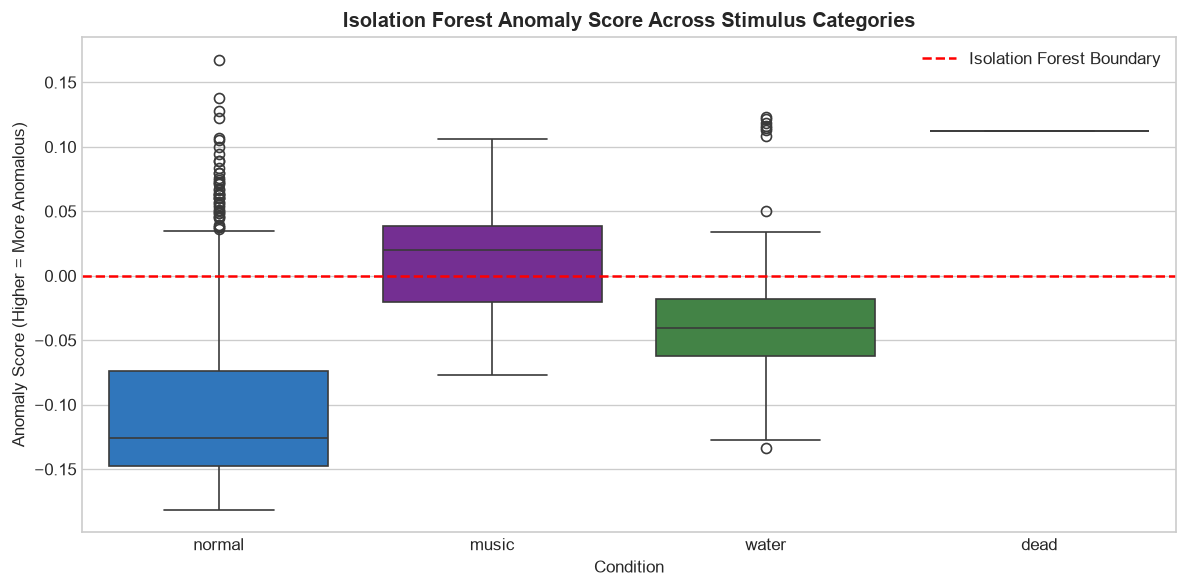

In [3]:
plt.figure(figsize=(10, 5))
palette = {"normal": "#1976D2", "music": "#7B1FA2", "water": "#388E3C", "dead": "#D32F2F"}

sns.boxplot(data=df, x="main_category", y="anomaly_score", palette=palette)
plt.axhline(0, color='red', linestyle='--', label='Isolation Forest Boundary')
plt.title("Isolation Forest Anomaly Score Across Stimulus Categories", fontweight='bold')
plt.ylabel("Anomaly Score (Higher = More Anomalous)")
plt.xlabel("Condition")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_anomaly_score_distribution.png"), dpi=300, bbox_inches='tight')
plt.show()


## 4. Anomaly Detection Rate Across Classes

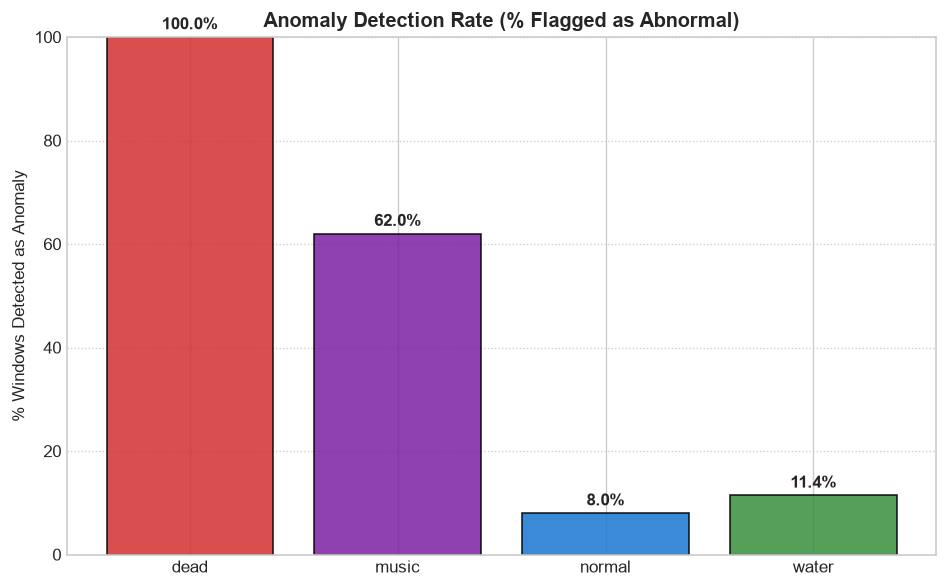

In [4]:
anomaly_rates = df.groupby("main_category")["is_anomaly_pred"].mean() * 100

plt.figure(figsize=(8, 5))
colors = [palette[cat] for cat in anomaly_rates.index]
bars = plt.bar(anomaly_rates.index, anomaly_rates.values, color=colors, alpha=0.85, edgecolor='k')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', fontweight='bold')

plt.title("Anomaly Detection Rate (% Flagged as Abnormal)", fontweight='bold')
plt.ylabel("% Windows Detected as Anomaly")
plt.ylim(0, 100)
plt.grid(True, linestyle=':', axis='y')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_anomaly_detection_rate.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. Timeline of Continuous Anomaly Detection

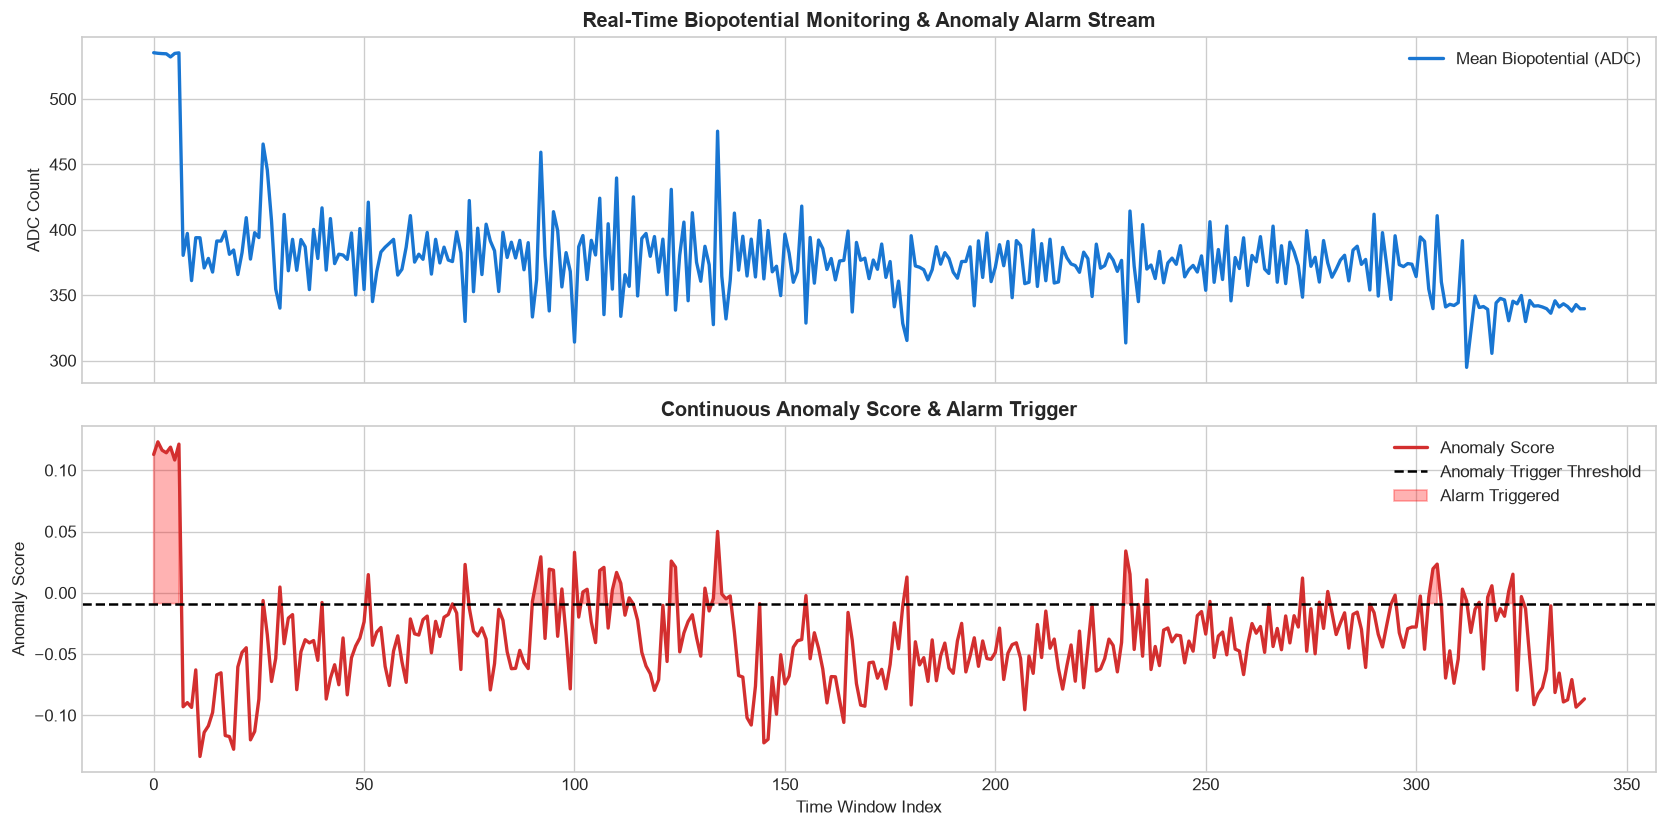

In [5]:
sample_session = df[df["main_category"] == "water"].copy()
if len(sample_session) < 50:
    sample_session = df.sample(150, random_state=42).sort_values("window_idx")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(sample_session["mean"].values, color='#1976D2', lw=2, label='Mean Biopotential (ADC)')
ax1.set_title("Real-Time Biopotential Monitoring & Anomaly Alarm Stream", fontweight='bold')
ax1.set_ylabel("ADC Count")
ax1.legend(loc='upper right')
ax1.grid(True)

scores = sample_session["anomaly_score"].values
threshold = np.percentile(df[df["main_category"] == "normal"]["anomaly_score"], 90)

ax2.plot(scores, color='#D32F2F', lw=2, label='Anomaly Score')
ax2.axhline(threshold, color='black', linestyle='--', label='Anomaly Trigger Threshold')
ax2.fill_between(range(len(scores)), scores, threshold, where=(scores > threshold), color='red', alpha=0.3, label='Alarm Triggered')

ax2.set_title("Continuous Anomaly Score & Alarm Trigger", fontweight='bold')
ax2.set_xlabel("Time Window Index")
ax2.set_ylabel("Anomaly Score")
ax2.legend(loc='upper right')
ax2.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_continuous_anomaly_timeline.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. ROC Evaluation of Unsupervised Anomaly Detection

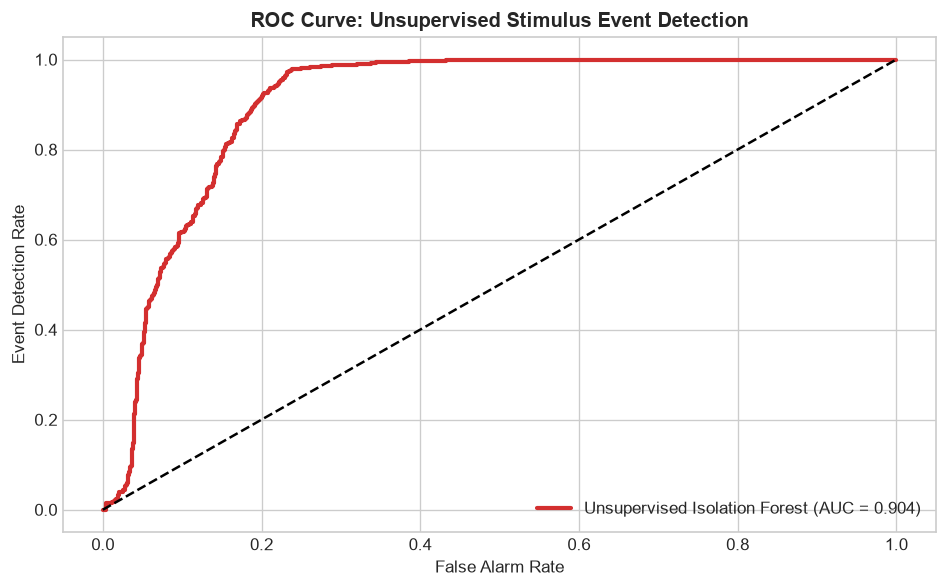

In [6]:
y_true_anomaly = (df["main_category"] != "normal").astype(int)
scores_all = df["anomaly_score"].values

fpr, tpr, _ = roc_curve(y_true_anomaly, scores_all)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, color='#D32F2F', lw=2.5, label=f'Unsupervised Isolation Forest (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.title("ROC Curve: Unsupervised Stimulus Event Detection", fontweight='bold')
plt.xlabel("False Alarm Rate")
plt.ylabel("Event Detection Rate")
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_anomaly_roc_curve.png"), dpi=300, bbox_inches='tight')
plt.show()
